# TP 4 Transformer -> Assembler et entraîner le modèle complet

Paul Pitiot, ING 3 Option IA Groupe B

## Objectif retenu

Assembler les briques des TP 1 à 3 (embeddings, attention multi-têtes, bloc pré-norm, unembedding) et entraîner le modèle sur Tiny Shakespeare, au caractère. Étapes du sujet : 0 constantes, 1 une tête, 2 plusieurs têtes, 3 un bloc, 4 couches du modèle, 5 passage avant et loss, 6 génération, 7 et 8 évaluation et entraînement, 9 entraîner, générer, expérimenter.

`idx (B, T) → token + position (B, T, C) → 4 blocs (B, T, C) → LayerNorm → lm_head (B, T, 65) → cross_entropy`

Livrable : une loss d'entraînement et de validation qui baisse, puis environ 2 000 caractères générés. Chaque étape est vérifiée par `assert`. Les graines sont fixées et seul `input.txt` est lu ; compter environ 12 minutes sur CPU, surtout pour les variantes de la partie 9.

## 0. Environnement et config

Les constantes du sujet gardent leur nom (les classes les lisent) ; celles propres au notebook sont en majuscules.

In [1]:
%matplotlib inline

import math
import os
import re
import time
import platform
from contextlib import contextmanager
from urllib.request import urlretrieve

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F

# ---- hyperparamètres du sujet (étape 0) ----
batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

# ---- config propre à ce notebook ----
SEED = 1337                         # graine du modèle et des tirages de batchs, comme dans les TP précédents
EVAL_SEED = 2024                    # graine des batchs de l'évaluation finale : tous les modèles sont mesurés sur le même tirage
N_COURT = 200                       # étape 9 : test très court avant l'entraînement complet
N_TEXTE = 2000                      # étape 9 : caractères générés après l'entraînement
INSTANTANES = (0, 500, 1000, 2000)  # itérations où l'on génère un court extrait pour suivre la progression
N_EXTRAIT = 300                     # longueur de ces extraits
EVAL_EVERY_ESSAI = 500              # variantes : évaluation moins fréquente que dans la boucle du sujet (100)
GRAINES_BRUIT = (SEED + 1, SEED + 2)  # variantes : deux graines de plus pour la référence, afin de mesurer le bruit

print(f"python {platform.python_version()} | torch {torch.__version__}")
print(f"SEED = {SEED} | EVAL_SEED = {EVAL_SEED} | N_COURT = {N_COURT} | N_TEXTE = {N_TEXTE}")

cpu
python 3.11.15 | torch 2.14.0
SEED = 1337 | EVAL_SEED = 2024 | N_COURT = 200 | N_TEXTE = 2000


## 1. Corpus fourni et étape 0

Le chargement et `get_batch` sont ceux du TP 1 (seul ajout : `.to(device)`).

In [2]:
# fourni : téléchargement, vocabulaire, découpage, get_batch (repris du TP 1, conservés tels quels)
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
if not os.path.exists("input.txt"):
    urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join([itos[i] for i in ids])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]


def get_batch(split):
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])
    y = torch.stack([data[i + 1 : i + block_size + 1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y


# contrôles : le corpus fourni est bien celui du TP 1
print(len(text), vocab_size, len(train_data), len(val_data))
assert len(text) == 1115394 and vocab_size == 65
assert decode(encode("hii there")) == "hii there"
torch.manual_seed(SEED)
xb, yb = get_batch("train")
print(xb.shape, yb.shape)
assert xb.shape == yb.shape == (batch_size, block_size)
assert (xb[:, 1:] == yb[:, :-1]).all()     # la cible est l'entrée décalée d'une position

1115394 65 1003854 111540
torch.Size([16, 32]) torch.Size([16, 32])


> *Commentaire - 1 :* le corpus est le même qu'au TP 1 (1 115 394 caractères, 65 distincts). `x` et `y` ont la forme `(16, 32)` et `y` est `x` décalé d'une position.

### Étape 0 : constantes

In [3]:
d_h = n_embd // n_head
tokens_par_batch = batch_size * block_size
print(f"d_h = n_embd / n_head = {n_embd} / {n_head} = {d_h}")
print(f"un batch : {batch_size} x {block_size} = {tokens_par_batch} tokens en entrée et autant de cibles, donc {tokens_par_batch} prédictions")
print(f"{max_iters} itérations lisent {max_iters * tokens_par_batch} tokens, soit {max_iters * tokens_par_batch / len(train_data):.1f} passage(s) sur le train")
assert d_h * n_head == n_embd

d_h = n_embd / n_head = 64 / 4 = 16
un batch : 16 x 32 = 512 tokens en entrée et autant de cibles, donc 512 prédictions
5000 itérations lisent 2560000 tokens, soit 2.6 passage(s) sur le train


**Questions**

- Calculez `d_h = n_embd / n_head`. Combien de tokens contient un batch ? Sur CPU, quelle variable réduiriez-vous d'abord pour tester ?

Réponses :

- On a `d_h = 64 / 4 = 16`.
- Un batch contient `16 × 32 = 512` tokens, soit 512 prédictions.
- Je réduis d'abord `max_iters` et `eval_iters`, car un `estimate_loss()` coûte autant que 100 itérations d'entraînement (partie 8).

## 2. Étape 1 : coder une tête

Scores `q·kᵀ / √d_h`, masque causal, softmax, puis `wei @ v`. Formes attendues pour `x` `(16, 32, 64)` : `q, k, v` `(16, 32, 16)`, `wei` `(16, 32, 32)`, sortie `(16, 32, 16)`.

In [4]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape                                         # x : (B,T,C)
        k, q = self.key(x), self.query(x)                         # (B,T,d_h) chacun
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5          # (B,T,d_h) @ (B,d_h,T) -> (B,T,T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))  # (B,T,T) : le futur passe à -inf
        wei = F.softmax(wei, dim=-1)                              # (B,T,T) : chaque ligne somme à 1
        wei = self.dropout(wei)
        v = self.value(x)                                         # (B,T,d_h)
        return wei @ v                                            # (B,T,T) @ (B,T,d_h) -> (B,T,d_h)

In [5]:
torch.manual_seed(SEED)
head = Head(d_h).to(device)
x = torch.randn(batch_size, block_size, n_embd, device=device)      # (16, 32, 64)
out = head(x)

# on refait le calcul étape par étape pour lire les formes intermédiaires
q, k, v = head.query(x), head.key(x), head.value(x)
wei = q @ k.transpose(-2, -1) * k.size(-1) ** -0.5
wei = wei.masked_fill(head.tril[:block_size, :block_size] == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)
print("x", tuple(x.shape), "| q, k, v", tuple(q.shape), "| wei", tuple(wei.shape), "| sortie", tuple(out.shape))

assert q.shape == k.shape == v.shape == (batch_size, block_size, d_h)
assert wei.shape == (batch_size, block_size, block_size)
assert out.shape == (batch_size, block_size, d_h)
assert torch.allclose(wei @ v, out, atol=1e-6)                                   # même calcul que forward
assert torch.allclose(wei.sum(dim=-1), torch.ones(batch_size, block_size, device=device), atol=1e-5)   # lignes normalisées
assert (wei.triu(1) == 0).all()                                                  # aucun poids sur le futur

# référence indépendante : l'attention causale de PyTorch
ref = F.scaled_dot_product_attention(q, k, v, is_causal=True)
print("écart max avec F.scaled_dot_product_attention :", (out - ref).abs().max().item())
assert torch.allclose(out, ref, atol=1e-5)

# causalité par perturbation : changer le token 20 ne modifie pas les sorties 0 à 19
x2 = x.clone()
x2[:, 20] = torch.randn(batch_size, n_embd, device=device)
out2 = head(x2)
print("écart max avant la position 20 :", (out[:, :20] - out2[:, :20]).abs().max().item(),
      "| après :", (out[:, 20:] - out2[:, 20:]).abs().max().item())
assert torch.allclose(out[:, :20], out2[:, :20], atol=1e-6)
assert not torch.allclose(out[:, 20:], out2[:, 20:])

x (16, 32, 64) | q, k, v (16, 32, 16) | wei (16, 32, 32) | sortie (16, 32, 16)
écart max avec F.scaled_dot_product_attention : 1.1920928955078125e-07
écart max avant la position 20 : 0.0 | après : 0.34880518913269043


> *Commentaire - 2 :* les formes sont celles du sujet. Les lignes de `wei` somment à 1, aucun poids ne porte sur le futur, et la sortie égale `F.scaled_dot_product_attention` (écart 1e-7). Changer le token 20 ne modifie aucune sortie avant la position 20.

In [6]:
# échelle : variance des scores q . k pour q, k de variance 1, selon le facteur choisi
torch.manual_seed(SEED)
qs = torch.randn(batch_size, block_size, d_h)
ks = torch.randn(batch_size, block_size, d_h)
brut = qs @ ks.transpose(-2, -1)
print(f"d_h = {d_h} et C = n_embd = {n_embd}")
for nom, facteur in (("sans échelle", 1.0), ("C**-0.5  (n_embd)", n_embd ** -0.5), ("k.size(-1)**-0.5  (d_h)", d_h ** -0.5)):
    print(f"{nom:<26} variance des scores : {(brut * facteur).var().item():.3f}")
assert abs((brut * d_h ** -0.5).var().item() - 1) < 0.15

# n_head = 1 : d_h = C, les deux facteurs coïncident
print("avec n_head = 1, d_h =", n_embd // 1, "= C")

d_h = 16 et C = n_embd = 64
sans échelle               variance des scores : 15.901
C**-0.5  (n_embd)          variance des scores : 0.248
k.size(-1)**-0.5  (d_h)    variance des scores : 0.994
avec n_head = 1, d_h = 64 = C


In [7]:
# tril[:T, :T] : un contexte plus court que block_size passe, un contexte plus long échoue
out5 = head(x[:, :5])
print("T = 5 :", tuple(out5.shape))
assert torch.allclose(out5, out[:, :5], atol=1e-6)     # le début d'un contexte ne dépend pas de la suite

try:
    head(torch.randn(batch_size, block_size + 1, n_embd, device=device))
except RuntimeError as e:
    print(f"T = {block_size + 1} :", str(e).splitlines()[0])

T = 5 : (16, 5, 16)
T = 33 : The size of tensor a (32) must match the size of tensor b (33) at non-singleton dimension 2


**Questions**

- Pourquoi `k.size(-1)` plutôt que `C` ? Pourquoi tronquer `tril[:T, :T]` ?

Réponses :

- On utilise `k.size(-1)` parce que le produit scalaire se fait sur `d_h = 16` composantes et non sur `C = 64`. La variance des scores vaut 15,9 sans échelle, 0,25 avec `C` et 0,99 avec `d_h`.
- On tronque `tril[:T, :T]` parce que le contexte peut être plus court que `block_size` (début de génération) : `T = 5` passe et `T = 33` échoue.

## 3. Étape 2 : combiner plusieurs têtes

Les 4 têtes de 16 composantes sont concaténées en 64, puis `proj` (la matrice `W_O`) mélange leurs informations.

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1
        )                                                  # 4 x (B,T,16) -> (B,T,64)
        return self.dropout(self.proj(out))                # W_O : (B,T,64) -> (B,T,64)

In [9]:
torch.manual_seed(SEED)
mha = MultiHeadAttention(n_head, d_h).to(device)
y = mha(x)
sorties_tetes = [h(x) for h in mha.heads]
concat = torch.cat(sorties_tetes, dim=-1)
print("une tête", tuple(sorties_tetes[0].shape), "| concaténation", tuple(concat.shape), "| après W_O", tuple(y.shape))
assert sorties_tetes[0].shape == (batch_size, block_size, d_h)
assert concat.shape == y.shape == (batch_size, block_size, n_embd)
assert torch.allclose(mha.proj(concat), y, atol=1e-6)

n_par = sum(p.numel() for p in mha.parameters())
print("paramètres :", n_par)
assert n_par == n_head * 3 * n_embd * d_h + n_embd * n_embd + n_embd       # Q, K, V de chaque tête + W_O et son biais

# concaténer ailleurs que sur la dernière dimension empile des positions au lieu de recoller des composantes
print("cat sur dim=1 :", tuple(torch.cat(sorties_tetes, dim=1).shape), "| sur dim=-1 :", tuple(concat.shape))

une tête (16, 32, 16) | concaténation (16, 32, 64) | après W_O (16, 32, 64)
paramètres : 16448
cat sur dim=1 : (16, 128, 16) | sur dim=-1 : (16, 32, 64)


In [10]:
# n_embd non divisible par n_head : 64 // 3 = 21 composantes par tête, 3 x 21 = 63 != 64
d_faux = n_embd // 3
mha_faux = MultiHeadAttention(3, d_faux).to(device)
print("d_h =", d_faux, "| concaténation :", 3 * d_faux, "composantes | W_O attend", n_embd)
try:
    mha_faux(x)
except RuntimeError as e:
    print(str(e).splitlines()[0])

d_h = 21 | concaténation : 63 composantes | W_O attend 64
mat1 and mat2 shapes cannot be multiplied (512x63 and 64x64)


**Questions**

- Pourquoi concaténer sur la dernière dimension ? Quel problème si `n_embd` n'est pas divisible par `n_head` ?

Réponses :

- On concatène sur la dernière dimension parce que c'est l'axe des composantes ; avec `dim=1`, on empilerait des positions et on obtiendrait `(16, 128, 16)`.
- Si `n_embd` n'est pas divisible par `n_head`, la concaténation n'a plus `n_embd` composantes : avec `n_head = 3`, `64 // 3 = 21` et `3 × 21 = 63`, donc `proj` échoue (`512x63` contre `64x64`).

> *Commentaire - 3 :* les formes sont 4 × `(16, 32, 16)`, puis `(16, 32, 64)`, puis `(16, 32, 64)`. Le module compte 16 448 paramètres (formule vérifiée).

## 4. Étape 3 : assembler un bloc

`FeedForward` du TP 3, et `Block` pré-norm : `x + sa(ln1(x))`, puis `x + ffwd(ln2(x))`.

In [11]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4*n_embd),
            nn.ReLU(),
            nn.Linear(4*n_embd, n_embd),
            nn.Dropout(dropout),
        )
    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))        # communication : (B,T,C) -> (B,T,C), les tokens s'échangent de l'information
        x = x + self.ffwd(self.ln2(x))      # calcul : (B,T,C) -> (B,T,C), chaque token séparément
        return x

In [12]:
torch.manual_seed(SEED)
bloc = Block(n_embd, n_head).to(device)
y = bloc(x)
print("entrée", tuple(x.shape), "| sortie", tuple(y.shape))
assert y.shape == x.shape == (batch_size, block_size, n_embd)

n_bloc = sum(p.numel() for p in bloc.parameters())
n_attention = sum(p.numel() for p in bloc.sa.parameters())
n_mlp = sum(p.numel() for p in bloc.ffwd.parameters())
n_ln = sum(p.numel() for p in (bloc.ln1.parameters())) + sum(p.numel() for p in bloc.ln2.parameters())
print(f"paramètres d'un bloc : {n_bloc} = attention {n_attention} + MLP {n_mlp} + 2 LayerNorm {n_ln}")
assert n_bloc == n_attention + n_mlp + n_ln

# perturbation : on change le token 5 de la séquence 0
x2 = x.clone()
x2[0, 5] = torch.randn(n_embd, device=device)
y2 = bloc(x2)
avant = (y[0, :5] - y2[0, :5]).abs().max().item()
apres = (y[0, 5:] - y2[0, 5:]).abs().amax(dim=-1).min().item()
autres_seq = (y[1:] - y2[1:]).abs().max().item()
print(f"positions 0 à 4 de la séquence 0 : écart max {avant:.1e} | positions 5 à 31 : plus petit écart max par position {apres:.1e} | autres séquences : {autres_seq:.1e}")
assert torch.allclose(y[0, :5], y2[0, :5], atol=1e-6)       # le passé ne voit pas le futur
assert apres > 0                                                 # chaque position suivante bouge
assert torch.equal(y[1:], y2[1:])                                # les séquences du batch sont indépendantes

# le MLP seul ne mélange pas les positions (TP 3), l'attention seule si : c'est elle qui relie les tokens
z = bloc.ln2(x)
mlp_a, mlp_b = bloc.ffwd(z), bloc.ffwd(bloc.ln2(x2))
print("MLP : positions autres que 5 inchangées :", torch.allclose(torch.cat([mlp_a[0, :5], mlp_a[0, 6:]]), torch.cat([mlp_b[0, :5], mlp_b[0, 6:]]), atol=1e-6))

entrée (16, 32, 64) | sortie (16, 32, 64)
paramètres d'un bloc : 49792 = attention 16448 + MLP 33088 + 2 LayerNorm 256
positions 0 à 4 de la séquence 0 : écart max 0.0e+00 | positions 5 à 31 : plus petit écart max par position 2.7e-02 | autres séquences : 0.0e+00
MLP : positions autres que 5 inchangées : True


**Questions**

- Dans quel ordre appliquer `LayerNorm`, attention/MLP et addition ? À quoi correspondent « communication » et « calcul » ?

Réponses :

- On applique `LayerNorm`, puis la sous-couche, puis on ajoute le résultat à l'entrée : `x + sous_couche(LayerNorm(x))`.
- La communication est l'attention, où les tokens échangent de l'information. Le calcul est le MLP, qui traite chaque token séparément.

> *Commentaire - 4 :* le bloc garde la forme `(16, 32, 64)` et compte 49 792 paramètres. Modifier le token 5 ne change ni les positions 0 à 4 ni les autres séquences : seule l'attention propage l'information, vers l'avant.

## 5. Étape 4 : définir les couches du modèle

Embeddings de token et de position, 4 blocs, `ln_f`, `lm_head`. Je garde le nom `BigramLanguageModel` du sujet ; la classe est complétée de cellule en cellule.

In [13]:
class BigramLanguageModel(nn.Module):    # nom du sujet, conservé : ce n'est plus un bigramme, le contexte est de block_size caractères
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

In [14]:
torch.manual_seed(SEED)
model = BigramLanguageModel().to(device)

W_tok = model.token_embedding_table.weight      # (vocab_size, n_embd)
W_pos = model.position_embedding_table.weight   # (block_size, n_embd)
W_lm = model.lm_head.weight                     # nn.Linear range (out, in) : (vocab_size, n_embd), la matrice d'unembedding est sa transposée
print("token_embedding_table  :", tuple(W_tok.shape))
print("position_embedding_table :", tuple(W_pos.shape))
print("lm_head.weight         :", tuple(W_lm.shape), "(transposée : ", tuple(W_lm.T.shape), ")")
assert W_tok.shape == (vocab_size, n_embd) and W_pos.shape == (block_size, n_embd) and W_lm.shape == (vocab_size, n_embd)
assert W_lm.data_ptr() != W_tok.data_ptr()          # deux matrices distinctes, pas de poids partagés

n_total = sum(p.numel() for p in model.parameters())
n_emb = W_tok.numel() + W_pos.numel()
n_blocs = sum(p.numel() for p in model.blocks.parameters())
n_sortie = sum(p.numel() for p in model.ln_f.parameters()) + sum(p.numel() for p in model.lm_head.parameters())
print(f"paramètres : {n_total} = embeddings {n_emb} + {n_layer} blocs {n_blocs} + sortie (ln_f + lm_head) {n_sortie}")
assert n_total == n_emb + n_blocs + n_sortie
print(f"soit {n_total / 1e6:.3f} M (TP 1 : {vocab_size ** 2} paramètres)")

token_embedding_table  : (65, 64)
position_embedding_table : (32, 64)
lm_head.weight         : (65, 64) (transposée :  (64, 65) )
paramètres : 209729 = embeddings 6208 + 4 blocs 199168 + sortie (ln_f + lm_head) 4353
soit 0.210 M (TP 1 : 4225 paramètres)


**Questions**

- Dimensions des trois matrices ? Pourquoi `lm_head` n'est-il plus confondu avec l'embedding ?

Réponses :

- Les trois matrices ont les dimensions `(65, 64)` pour `token_embedding_table`, `(32, 64)` pour `position_embedding_table` et `(65, 64)` pour `lm_head` (`(64, 65)` une fois transposée).
- `lm_head` n'est plus confondu avec l'embedding parce que les rôles diffèrent : le caractère devient un vecteur, les blocs le contextualisent, puis `lm_head` le projette sur le vocabulaire. Au TP 1, une seule table `65 × 65` faisait tout.

> *Commentaire - 5 :* le modèle compte 209 729 paramètres (4 225 au TP 1), presque tous dans les blocs (199 168).

## 6. Étape 5 : écrire le passage avant et la loss

On additionne les deux embeddings, puis blocs, `ln_f` et `lm_head`. Les logits ne sont aplatis en `(B·T, 65)` que si des cibles sont fournies.

In [15]:
def forward(self, idx, targets=None):
    B, T = idx.shape

    tok_emb = self.token_embedding_table(idx)      # (B,T,C)
    pos = torch.arange(T, device=idx.device)
    pos_emb = self.position_embedding_table(pos)   # (T,C)

    x = tok_emb + pos_emb                          # (B,T,C)
    x = self.blocks(x)                             # (B,T,C)
    x = self.ln_f(x)                               # (B,T,C)
    logits = self.lm_head(x)                       # (B,T,vocab_size)

    if targets is None:
        loss = None
    else:
        logits = logits.reshape(B*T, vocab_size)   # (B*T,vocab_size)
        targets = targets.reshape(B*T)             # (B*T,)
        loss = F.cross_entropy(logits, targets)
    return logits, loss


BigramLanguageModel.forward = forward      # la classe est complétée étape par étape, comme dans le sujet

In [16]:
torch.manual_seed(SEED)
xb, yb = get_batch("train")
logits_seuls, perte_none = model(xb)
logits_aplatis, loss = model(xb, yb)
print("sans cibles :", tuple(logits_seuls.shape), perte_none, "| avec cibles :", tuple(logits_aplatis.shape), loss.item())
assert logits_seuls.shape == (batch_size, block_size, vocab_size) and perte_none is None
assert logits_aplatis.shape == (batch_size * block_size, vocab_size)
assert torch.equal(logits_aplatis, logits_seuls.reshape(-1, vocab_size))

# la loss est bien la moyenne de -log P(cible), formule du cours (p. 77 et 78)
logp = F.log_softmax(logits_seuls, dim=-1)
a_la_main = -logp.gather(-1, yb.unsqueeze(-1)).mean()
assert torch.allclose(a_la_main, loss, atol=1e-6)

# l'addition des deux embeddings : (B,T,C) + (T,C), la même position ajoutée à chaque séquence
tok_emb = model.token_embedding_table(xb)
pos_emb = model.position_embedding_table(torch.arange(block_size, device=device))
somme = tok_emb + pos_emb
print("tok_emb", tuple(tok_emb.shape), "+ pos_emb", tuple(pos_emb.shape), "->", tuple(somme.shape))
assert all(torch.equal(somme[b], tok_emb[b] + pos_emb) for b in range(batch_size))

# aplatir avant la génération ferait perdre l'axe du temps
try:
    logits_aplatis[:, -1, :]
except IndexError as e:
    print("logits aplatis [:, -1, :] :", e)

# perte initiale, moyenne sur 50 batchs, contre ln(vocab_size)
with torch.no_grad():
    pertes = torch.tensor([model(*get_batch("train"))[1].item() for _ in range(50)])
print(f"perte initiale : {pertes.mean().item():.3f} (écart-type {pertes.std().item():.3f}) | ln({vocab_size}) = {math.log(vocab_size):.3f}")

# pourquoi pas exactement ln(65) : des logits d'écart-type s font monter la loss d'environ s^2 / 2 (cibles indépendantes des logits)
var_logits = logits_seuls.var().item()
print(f"variance des logits à l'initialisation : {var_logits:.3f} -> ln({vocab_size}) + variance / 2 = {math.log(vocab_size) + var_logits / 2:.3f}")

sans cibles : (16, 32, 65) None | avec cibles : (512, 65) 4.390261173248291
tok_emb (16, 32, 64) + pos_emb (32, 64) -> (16, 32, 64)
logits aplatis [:, -1, :] : too many indices for tensor of dimension 2


perte initiale : 4.409 (écart-type 0.030) | ln(65) = 4.174
variance des logits à l'initialisation : 0.347 -> ln(65) + variance / 2 = 4.348


**Questions**

- Quelle règle de broadcasting permet l'addition ? Pourquoi ne pas aplatir les logits à la génération ?

Réponses :

- Le broadcasting complète `pos_emb` `(T, C)` en `(1, T, C)`, puis le répète sur les `B` séquences.
- On n'aplatit pas les logits à la génération parce qu'on lit `logits[:, -1, :]` : une fois aplatis, l'axe du temps n'existe plus (erreur montrée).

> *Commentaire - 6 :* les logits sont `(16, 32, 65)` sans cibles et `(512, 65)` avec. La loss égale la moyenne de `-log P(cible)` recalculée à la main. La loss initiale vaut 4,41 pour `ln(65) = 4,17` : des logits de variance 0,35 la font monter d'environ variance/2 (4,35 prévu).

## 7. Étape 6 : générer avec un contexte limité

On garde la fin du contexte (`idx[:, -block_size:]`), on prend le dernier pas de temps, on tire avec `multinomial` et on réinjecte.

In [17]:
@torch.no_grad()
def generate(self, idx, max_new_tokens):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -block_size:]                 # (B,T') avec T' <= block_size : la fin du contexte
        logits, _ = self(idx_cond)                      # (B,T',vocab_size)

        logits = logits[:, -1, :]                       # (B,vocab_size) : le dernier pas de temps
        probs = F.softmax(logits, dim=-1)               # (B,vocab_size)
        idx_next = torch.multinomial(
            probs, num_samples=1
        )                                               # (B,1)
        idx = torch.cat((idx, idx_next), dim=1)         # (B,T+1)
    return idx


BigramLanguageModel.generate = generate

In [18]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
torch.manual_seed(SEED)
a = model.generate(context, max_new_tokens=300)
torch.manual_seed(SEED)
b = model.generate(context, max_new_tokens=300)
print(a.shape)
print(decode(a[0, :120].tolist()))
assert a.shape == (1, 301) and a[0, 0].item() == 0
assert 0 <= a.min().item() and a.max().item() < vocab_size
assert torch.equal(a, b)                                  # même graine, même texte

# le contexte dépasse block_size (301 > 32) : sans le rognage idx[:, -block_size:], la table de positions déborde
try:
    model(a)
except IndexError as e:
    print(f"contexte de {a.shape[1]} tokens sans rognage :", e)

# no_grad : pas de graphe de calcul pendant la génération
sortie_grad, _ = model(context)
with torch.no_grad():
    sortie_nograd, _ = model(context)
print("requires_grad avec / sans no_grad :", sortie_grad.requires_grad, "/", sortie_nograd.requires_grad)

torch.Size([1, 301])

jpzlYoSy;czdeL'YEiI,YzrzPGu-?YeNY
ijbo
LzzXzeUtS-A.U$FPsVbiG HTUsPUe$,pe$zOAnsz-imKzcAkfJfYSgUpRTNBE:myOzk. qVh -gLcJJl
contexte de 301 tokens sans rognage : index out of range in self
requires_grad avec / sans no_grad : True / False


**Questions**

- Pourquoi `@torch.no_grad()` ? Pourquoi `multinomial` plutôt qu'`argmax` ?

Réponses :

- On utilise `@torch.no_grad()` parce qu'il n'y a pas de rétropropagation à la génération : on évite de construire le graphe de calcul (mémoire et temps).
- On échantillonne avec `multinomial` parce qu'`argmax` donne toujours le même texte et boucle (mesuré en partie 11).

> *Commentaire - 7 :* `generate` renvoie `(1, 301)` pour 300 tokens demandés, et la même graine donne le même texte. Sans le rognage, un contexte de 301 tokens déborde de la table de positions (erreur montrée). Avant l'entraînement, le texte est un charabia.

## 8. Étapes 7 et 8 : évaluer puis entraîner

`estimate_loss` (fournie) moyenne la loss sur 200 batchs par split, en mode `eval()`. La boucle du sujet est complétée avec `loss.backward()` et `optimizer.step()`, dans une fonction `train` qui garde aussi l'historique. Test très court d'abord, puis entraînement complet.

In [19]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out


# fourni : utilise le `model` global. Sur le modèle non entraîné :
torch.manual_seed(EVAL_SEED)
avant = estimate_loss()
print({k: round(v.item(), 4) for k, v in avant.items()}, "| ln(65) =", round(math.log(vocab_size), 4))

{'train': 4.409, 'val': 4.4008} | ln(65) = 4.1744


In [20]:
def extrait(n=N_EXTRAIT):
    # n caractères depuis "\n", sans toucher au générateur aléatoire de l'entraînement
    etat = torch.get_rng_state()
    model.eval()
    ctx = torch.zeros((1, 1), dtype=torch.long, device=device)
    texte = decode(model.generate(ctx, max_new_tokens=n)[0].tolist())
    model.train()
    torch.set_rng_state(etat)
    return texte


def train(n_iters, eval_every, snapshots=(), verbose=True):
    # la boucle du sujet (étapes 7 et 8), sur le `model` global ; je garde en plus les losses et quelques extraits
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate
    )
    historique, extraits = [], {}
    for iteration in range(n_iters):
        if iteration % eval_every == 0:
            pertes = estimate_loss()
            historique.append((iteration, pertes['train'].item(), pertes['val'].item()))
            if verbose:
                print(f"iter {iteration:4d} | train {pertes['train']:.4f} | val {pertes['val']:.4f}")
        if iteration in snapshots:
            extraits[iteration] = extrait()

        xb, yb = get_batch('train')
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    return historique, extraits


def eval_final():
    # mesure finale sur un tirage de batchs fixe (EVAL_SEED) : tous les modèles sont comparés sur la même loterie
    torch.manual_seed(EVAL_SEED)
    pertes = estimate_loss()
    return pertes['train'].item(), pertes['val'].item()

In [21]:
# test très court sur un modèle jetable : la loss baisse-t-elle, et combien coûte une itération ?
torch.manual_seed(SEED)
model = BigramLanguageModel().to(device)

t0 = time.time(); estimate_loss(); t_eval = time.time() - t0
t0 = time.time(); hist_court, _ = train(N_COURT, eval_every=N_COURT); t_court = time.time() - t0 - t_eval
tr, va = eval_final()
print(f"{N_COURT} itérations : train {hist_court[0][1]:.3f} -> {tr:.3f} | val {hist_court[0][2]:.3f} -> {va:.3f}")
print(f"coût (à titre indicatif) : {100 * t_court / N_COURT:.2f} s pour 100 itérations d'entraînement, {t_eval:.2f} s pour un estimate_loss()")
assert tr < hist_court[0][1] and va < hist_court[0][2]

iter    0 | train 4.4119 | val 4.4042


200 itérations : train 4.412 -> 2.497 | val 4.404 -> 2.490
coût (à titre indicatif) : 1.49 s pour 100 itérations d'entraînement, 1.62 s pour un estimate_loss()


In [22]:
torch.manual_seed(SEED)
model = BigramLanguageModel().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M paramètres")

historique, extraits = train(max_iters, eval_interval, snapshots=INSTANTANES)
train_final, val_final = eval_final()
print(f"fin : train {train_final:.4f} | val {val_final:.4f}")

0.209729 M paramètres


iter    0 | train 4.4109 | val 4.4016


iter  100 | train 2.6511 | val 2.6604


iter  200 | train 2.4941 | val 2.4902


iter  300 | train 2.3905 | val 2.4020


...

iter 4600 | train 1.6786 | val 1.8195


iter 4700 | train 1.6749 | val 1.8286


iter 4800 | train 1.6668 | val 1.8372


iter 4900 | train 1.6640 | val 1.8241


fin : train 1.6632 | val 1.8174


> *Commentaire - 8 :* le test court (200 itérations) fait passer la loss de 4,41 à 2,50. Pendant l'entraînement complet, la validation passe à 2,27 (itération 500), 1,97 (2 000), 1,85 (4 000), puis 1,817 à la fin (train 1,663). Le coût indicatif est d'environ 1,5 s pour 100 itérations et pour un `estimate_loss()`.

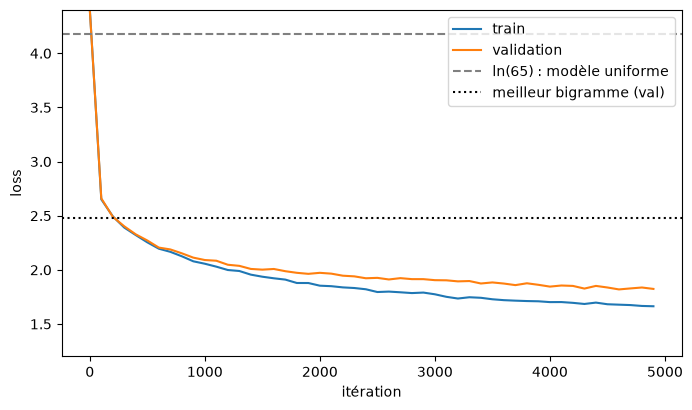

table de comptage (TP 1) : train 2.455 | val 2.482
perte de validation minimale : 1.8195 à l'itération 4600
dernière évaluation de la boucle (iter 4900) : train 1.6640 | val 1.8241
mesure finale (EVAL_SEED) : train 1.6632 | val 1.8174 | écart val - train +0.1542
perplexité de validation : 6.16 (uniforme : 65)


In [23]:
hist = pd.DataFrame(historique, columns=["iteration", "train", "val"])

# plancher du TP 1 : la meilleure table de bigrammes (comptage sur le train, +1 de lissage)
counts = torch.ones(vocab_size, vocab_size)
counts.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
p_bigramme = counts / counts.sum(dim=1, keepdim=True)
loss_bigramme_val = -torch.log(p_bigramme[val_data[:-1], val_data[1:]]).mean().item()
loss_bigramme_train = -torch.log(p_bigramme[train_data[:-1], train_data[1:]]).mean().item()

plt.figure(figsize=(8, 4.5))
plt.plot(hist["iteration"], hist["train"], label="train")
plt.plot(hist["iteration"], hist["val"], label="validation")
plt.axhline(math.log(vocab_size), linestyle="--", color="gray", label="ln(65) : modèle uniforme")
plt.axhline(loss_bigramme_val, linestyle=":", color="black", label="meilleur bigramme (val)")
plt.xlabel("itération")
plt.ylabel("loss")
plt.ylim(1.2, 4.4)
plt.legend()
plt.show()

i_min = hist["val"].idxmin()
print(f"table de comptage (TP 1) : train {loss_bigramme_train:.3f} | val {loss_bigramme_val:.3f}")
print(f"perte de validation minimale : {hist.loc[i_min, 'val']:.4f} à l'itération {int(hist.loc[i_min, 'iteration'])}")
print(f"dernière évaluation de la boucle (iter {int(hist['iteration'].iloc[-1])}) : train {hist['train'].iloc[-1]:.4f} | val {hist['val'].iloc[-1]:.4f}")
print(f"mesure finale (EVAL_SEED) : train {train_final:.4f} | val {val_final:.4f} | écart val - train {val_final - train_final:+.4f}")
print(f"perplexité de validation : {math.exp(val_final):.2f} (uniforme : {vocab_size})")
assert hist["train"].iloc[-1] < hist["train"].iloc[0] and hist["val"].iloc[-1] < hist["val"].iloc[0]

> *Commentaire - 9 :* train et validation baissent ensemble et passent sous le meilleur bigramme du TP 1 (2,48) dès l'itération 300. La perplexité de validation vaut 6,2 (65 pour un modèle uniforme). L'écart validation moins train grandit (0,03 à 1 000, 0,15 à la fin), mais la validation ne remonte pas : il n'y a pas de surapprentissage.

In [24]:
@contextmanager
def hyper(**kw):
    # change temporairement des variables globales (block_size, n_head, dropout, model...) : les classes du sujet les lisent
    g = globals()
    ancien = {k: g[k] for k in kw if k in g}
    g.update(kw)
    try:
        yield
    finally:
        for k in kw:
            if k in ancien:
                g[k] = ancien[k]
            else:
                del g[k]


# contrôle : les globales changent le temps du bloc, puis sont restaurées
with hyper(block_size=16, n_head=1):
    assert (block_size, n_head) == (16, 1)
assert (block_size, n_head, dropout, batch_size) == (32, 4, 0.0, 16)
print("globales restaurées :", block_size, n_head, dropout, batch_size)

globales restaurées : 32 4 0.0 16


In [25]:
# eval() / train() : avec dropout > 0, deux passes sur la même entrée diffèrent en mode train et coïncident en mode eval
with hyper(dropout=0.2):
    torch.manual_seed(SEED)
    m_do = BigramLanguageModel().to(device)
xb, yb = get_batch("train")
m_do.train()
_, l_a = m_do(xb, yb)
_, l_b = m_do(xb, yb)
m_do.eval()
_, l_c = m_do(xb, yb)
_, l_d = m_do(xb, yb)
print(f"dropout = 0,2, mode train : {l_a.item():.4f} puis {l_b.item():.4f} | mode eval : {l_c.item():.4f} puis {l_d.item():.4f}")
assert l_a.item() != l_b.item() and l_c.item() == l_d.item()

dropout = 0,2, mode train : 4.3844 puis 4.3740 | mode eval : 4.3815 puis 4.3815


**Questions**

- Pourquoi `model.eval()` puis `model.train()` ? Si la loss train baisse et que la validation remonte ?

Réponses :

- On appelle `model.eval()` pour désactiver le dropout et mesurer le modèle complet, puis `model.train()` pour le réactiver. Avec `dropout = 0,2`, deux passes identiques donnent 4,3844 puis 4,3740 en `train`, et 4,3815 deux fois en `eval`.
- Si la loss train baisse et que la validation remonte, le modèle apprend le train par cœur : c'est du surapprentissage. Ce n'est pas le cas ici.

## 9. Étape 9 : entraîner, générer et expérimenter

Texte avant et après entraînement, losses (parties 8 et 9), puis variantes du sujet (points 3 à 5). Pour juger le texte autrement qu'à l'œil, je mesure la part des mots générés présents dans le texte d'entraînement.

In [26]:
context = torch.zeros(
    (1, 1), dtype=torch.long, device=device
)
model.eval()
torch.manual_seed(SEED)
result = model.generate(context, max_new_tokens=N_TEXTE)
texte_final = decode(result[0].tolist())
print(texte_final)
model.train()
assert len(texte_final) == N_TEXTE + 1


COMINES:
You weaEd in roling heave than poor the bod with in with this
bast nothims cold frights in coyful. Go, some in that somorrow why delivist
of his now; thy safest
Woutst and sure with pleasonest hart thosese me
To
As in an hit; mether nose blood posty
the putury losgize.

Cly Margent:
Will gom vent my,
And for and his somether.
And thee: how issees, that out; do part of me.

FRIAR My God.
Awail
the go mintle.

Seconawher:
Suchmance.

BENRY:
What, by proyal not behier. Mast, thouch give not.

LORATET:
My mothing mine; and beason to my bort-just?
Romander 'twas thee ever his sheign.

LUCENTIO:
So moody are threspary as whomes;
Had, they confessfect or Stral whose
To,
Why, lad-as whose you? no, you shouldy.

KING HORTKENBY VI

MENENIUS:
Vattes to lews my
Pliak the the father;
But for fliec; oft, I sir; to were towen tleams. Hammne,
A prout unenpeth, But revest Palains a death?
How the nigh off witee. What you unsweethought:
You is your, and but of the hrour strope!
All never-grami

In [27]:
for it in INSTANTANES:
    print(f"----- itération {it} -----")
    print(extraits[it][:200])

----- itération 0 -----

Q;rJvbwlnGl$;kvqYUul;xvkeJk!;VNzPtsVDQGStokz;hXBPlse&nEpDRW,VNJNcqKDb!R,lhiEoNfRqVcXKbCVc,YIoKXtcEHoeJ-&ZQcJwdPzhloXk-Ta-KhT.PZhDdzwb,WOd!hepNDHrHJJ?OEhWFN?pXuNV;CPNo&pbb;Hss!ot$cCPpM:oOe-iKzw-?kFlyM
----- itération 500 -----

CLAnd'
FIUS:
Save diligh ave, mer fo hind, and hit in nove thar wellLe your btou,
ourerer thild ho show Dio you ha ant weu moneld avere
thare, erof eur sfoc 'ser akeit,
Wherts bBurs? thider ieneagh t
----- itération 1000 -----

And my princent,'dy's neart: muth now lay.

KINGOK:
Norule thal spond?'te.

LONUS:
Thict nockch:
And levey ghenong hos sellofe thees celaysh ig,
Wnate knowh a to myourglistse'st,
His is oullynis to b
----- itération 2000 -----

I all we slove, cask the patnrang toble,
God lave voorstiles thee but hange:
It all ladded My for hench
their fuimal, if the men convetans to he is in exer.

GULA:
Boy lie his cold to there of we: mi


In [28]:
# une mesure du « style reconnaissable » : part des mots générés qui existent dans le texte d'entraînement
MOTS = set(re.findall(r"[a-z']+", text[:n].lower()))


def taux_mots(t):
    mots = re.findall(r"[a-z']+", t.lower())
    return sum(m in MOTS for m in mots) / max(len(mots), 1), len(mots)


def generer_bigramme(longueur):
    # génération par la table de comptage du TP 1 (même contexte de départ)
    ids = [0]
    for _ in range(longueur):
        ids.append(torch.multinomial(p_bigramme[ids[-1]], 1).item())
    return decode(ids)


torch.manual_seed(SEED)
sources = {
    "avant entraînement (itération 0)": extraits[0],
    "table de bigrammes par comptage": generer_bigramme(N_TEXTE),
    f"transformer, itération 2000": extraits[2000],
    "transformer, fin (5000 itérations)": texte_final,
    "vrai texte (2000 caractères de val)": decode(val_data[:N_TEXTE].tolist()),
}
print(f"{'source':<40} {'mots':>5} {'mots connus':>12}")
for nom, t in sources.items():
    taux, nb = taux_mots(t)
    print(f"{nom:<40} {nb:>5} {taux:>12.1%}")

source                                    mots  mots connus
avant entraînement (itération 0)            38         5.3%
table de bigrammes par comptage            356        14.0%
transformer, itération 2000                 60        60.0%
transformer, fin (5000 itérations)         365        67.7%
vrai texte (2000 caractères de val)        358        97.5%


> *Commentaire - 10 :* le texte final a la forme d'une pièce (noms en majuscules suivis de `:`, vers courts) mais n'a pas de sens, ce qui est attendu. Il passe du charabia (itération 0) aux noms et mots courts (500 à 1 000), puis à plus de mots entiers.
>
> Les mots connus du texte d'entraînement représentent 5,3 % avant l'entraînement, 14,0 % pour le bigramme du TP 1, 67,7 % à la fin et 97,5 % pour du vrai texte.

### Variantes du sujet (points 3 à 5)

Chaque variante est un modèle neuf, avec le même budget (5 000 itérations). La référence est entraînée sur 3 graines pour connaître le bruit. `block_size` change aussi le nombre de tokens par batch : j'ajoute deux contrôles à 512 tokens par batch.

In [29]:
def essai(nom, seed=SEED, **hp):
    # entraîne un modèle neuf avec les hyperparamètres modifiés (même budget : max_iters itérations) et le mesure
    with hyper(**hp):
        torch.manual_seed(seed)
        m = BigramLanguageModel().to(device)
        with hyper(model=m):
            hist, _ = train(max_iters, EVAL_EVERY_ESSAI, verbose=False)
            tr, va = eval_final()
            model.eval()
            torch.manual_seed(EVAL_SEED)
            t = decode(model.generate(torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=1000)[0].tolist())
    return {
        "nom": nom, "params": sum(p.numel() for p in m.parameters()),
        "tokens/batch": hp.get("batch_size", batch_size) * hp.get("block_size", block_size),
        "train": tr, "val": va, "val - train": va - tr, "mots connus": taux_mots(t)[0],
        "courbe": hist,
    }




In [30]:
EXPERIENCES = [(f"référence, graine {s}", s, {}) for s in GRAINES_BRUIT] + [
    ("block_size = 16", SEED, {"block_size": 16}),
    ("block_size = 64", SEED, {"block_size": 64}),
    ("block_size = 16, batch_size = 32", SEED, {"block_size": 16, "batch_size": 32}),
    ("block_size = 64, batch_size = 8", SEED, {"block_size": 64, "batch_size": 8}),
    ("n_head = 1  (d_h = 64)", SEED, {"n_head": 1}),
    ("dropout = 0,2", SEED, {"dropout": 0.2}),
]

resultats = [{
    "nom": f"référence, graine {SEED} (run principal)", "params": sum(p.numel() for p in model.parameters()),
    "tokens/batch": batch_size * block_size, "train": train_final, "val": val_final,
    "val - train": val_final - train_final, "mots connus": taux_mots(texte_final[:1001])[0],
    "courbe": historique,
}]
for nom, seed, hp in EXPERIENCES:
    r = essai(nom, seed, **hp)
    resultats.append(r)
    print(f"{nom:<36} val {r['val']:.4f}")

tableau = pd.DataFrame(resultats).drop(columns="courbe").set_index("nom")
print()
print(tableau.round(4).to_string())
assert block_size == 32 and n_head == 4 and dropout == 0.0 and batch_size == 16     # les globales du sujet sont restaurées

référence, graine 1338               val 1.8065


référence, graine 1339               val 1.8037


block_size = 16                      val 1.9089


block_size = 64                      val 1.7646


block_size = 16, batch_size = 32     val 1.8464


block_size = 64, batch_size = 8      val 1.8230


n_head = 1  (d_h = 64)               val 1.8257


dropout = 0,2                        val 1.9072

                                        params  tokens/batch   train     val  val - train  mots connus
nom                                                                                                   
référence, graine 1337 (run principal)  209729           512  1.6632  1.8174       0.1542       0.6796
référence, graine 1338                  209729           512  1.6444  1.8065       0.1621       0.6477
référence, graine 1339                  209729           512  1.6422  1.8037       0.1615       0.7446
block_size = 16                         208705           256  1.7527  1.9089       0.1562       0.6307
block_size = 64                         211777          1024  1.5841  1.7646       0.1805       0.7322
block_size = 16, batch_size = 32        208705           512  1.6729  1.8464       0.1735       0.7377
block_size = 64, batch_size = 8         211777           512  1.6869  1.8230       0.1361       0.6649
n_head = 1  (d_h = 64)  

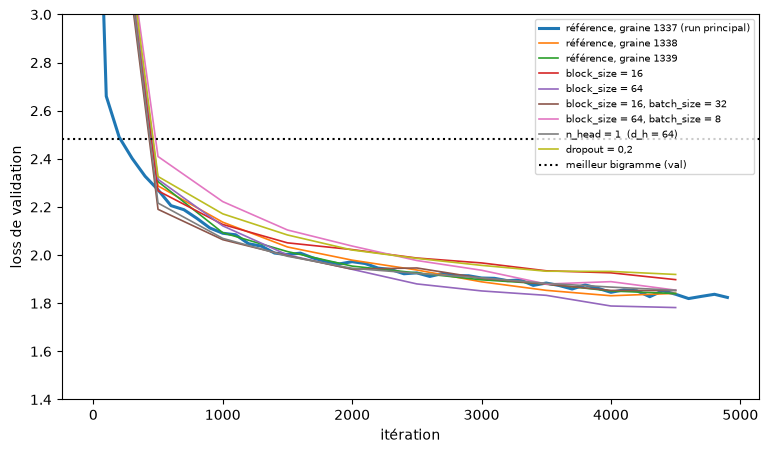

référence (3 graines) : val 1.8092 +/- 0.0072 (écart-type) | train 1.6500 | écart val - train +0.1593

variante                              val     écart à la moyenne de référence  (en écarts-types)
block_size = 16                      1.9089  +0.0996  (+13.8)
block_size = 64                      1.7646  -0.0446  (-6.2)
block_size = 16, batch_size = 32     1.8464  +0.0372  (+5.1)
block_size = 64, batch_size = 8      1.8230  +0.0138  (+1.9)
n_head = 1  (d_h = 64)               1.8257  +0.0165  (+2.3)
dropout = 0,2                        1.9072  +0.0980  (+13.6)


In [31]:
plt.figure(figsize=(9, 5))
for r in resultats:
    h = pd.DataFrame(r["courbe"], columns=["iteration", "train", "val"])
    plt.plot(h["iteration"], h["val"], label=r["nom"], linewidth=2.2 if "run principal" in r["nom"] else 1.2)
plt.axhline(loss_bigramme_val, linestyle=":", color="black", label="meilleur bigramme (val)")
plt.xlabel("itération")
plt.ylabel("loss de validation")
plt.ylim(1.4, 3.0)
plt.legend(fontsize=7)
plt.show()

ref = tableau[tableau.index.str.startswith("référence")]
moy, ecart = ref["val"].mean(), ref["val"].std()
print(f"référence (3 graines) : val {moy:.4f} +/- {ecart:.4f} (écart-type) | train {ref['train'].mean():.4f} | écart val - train {ref['val - train'].mean():+.4f}")
variantes = tableau[~tableau.index.str.startswith("référence")]
print("\nvariante                              val     écart à la moyenne de référence  (en écarts-types)")
for nom, ligne in variantes.iterrows():
    print(f"{nom:<36} {ligne['val']:.4f}  {ligne['val'] - moy:+.4f}  ({(ligne['val'] - moy) / ecart:+.1f})")

> *Commentaire - 11 :*
> - Bruit : la référence donne 1,809 ± 0,007 en validation sur 3 graines.
> - `block_size` : 16 donne 1,909 et 64 donne 1,765, mais à 512 tokens par batch on obtient 1,846 et 1,823. L'écart venait surtout du nombre de tokens lus, et 64 ne gagne rien à budget égal.
> - Têtes : une tête donne 1,826 contre 1,809 pour quatre. L'écart est trop proche du bruit (une graine) pour trancher.
> - Dropout : 0,2 donne 1,907, ce qui est moins bon, car il n'y a pas de surapprentissage à corriger.
>
> Limites : chaque variante n'a qu'une graine et 5 000 itérations.

## 10. Bilan des quatre TP

| Brique | Notion du cours | Rôle |
|---|---|---|
| `token_embedding_table` | matrice d'embedding (p. 15) | transforme un token en vecteur |
| `position_embedding_table` | embedding de position (p. 16) | ajoute la place du token |
| `Head`, `MultiHeadAttention` | Query, Key, masque, Values, multi-têtes (p. 36 à 51) | crée le contexte |
| `FeedForward` | MLP (p. 57, 62 à 68) | calcule sur chaque token séparément |
| `LayerNorm`, résiduel, `Block` | normalisation, `E' = E + ΔE` (p. 58, 59, 69) | stabilise et enchaîne attention et MLP |
| `lm_head` | unembedding (p. 26 à 28) | un score par caractère |
| `cross_entropy`, `backward`, `AdamW` | loss `-log P`, rétropropagation (p. 77 à 82) | mesure l'erreur et corrige les poids |

- **Quelle brique crée le contexte ?** L'attention crée le contexte : c'est la seule brique qui fait circuler l'information entre les positions.
- **Laquelle transforme un token ?** `token_embedding_table` transforme un token (identifiant → vecteur), puis `FeedForward` transforme chaque vecteur.
- **Laquelle produit les logits ?** `lm_head` produit les logits.
- **Où la loss agit-elle ?** La loss est calculée sur les logits, mais `backward` envoie le gradient à tous les paramètres : 94 tenseurs sur 94 (partie 11).

## 11. Analyse

Quatre vérifications : reproductibilité, causalité du modèle entraîné, gradients, `argmax` contre `multinomial`.

In [32]:
# 1) reproductibilité : même graine, mêmes poids après 50 itérations ; autre graine, autres poids
def court(seed, n_iters=50):
    torch.manual_seed(seed)
    m = BigramLanguageModel().to(device)
    with hyper(model=m):
        train(n_iters, eval_every=n_iters, verbose=False)
    return m


m1, m2, m3 = court(SEED), court(SEED), court(SEED + 1)
memes = all(torch.equal(a, b) for a, b in zip(m1.parameters(), m2.parameters()))
autres = any(not torch.equal(a, b) for a, b in zip(m1.parameters(), m3.parameters()))
print("même graine : poids identiques :", memes, "| graine + 1 : poids différents :", autres)
assert memes and autres

même graine : poids identiques : True | graine + 1 : poids différents : True


In [33]:
# 2) causalité du modèle complet entraîné : changer le caractère 20 ne change aucune prédiction avant la position 20
model.eval()
xb, _ = get_batch("val")
xb2 = xb.clone()
xb2[:, 20] = (xb2[:, 20] + 1) % vocab_size
with torch.no_grad():
    l1, _ = model(xb)
    l2, _ = model(xb2)
avant = (l1[:, :20] - l2[:, :20]).abs().max().item()
apres = (l1[:, 20:] - l2[:, 20:]).abs().amax(dim=(0, 2)).min().item()
print(f"écart max des logits avant la position 20 : {avant:.1e} | écart min par position à partir de 20 : {apres:.1e}")
assert torch.allclose(l1[:, :20], l2[:, :20], atol=1e-5)
assert apres > 0
_ = model.train()

écart max des logits avant la position 20 : 0.0e+00 | écart min par position à partir de 20 : 3.4e-01


In [34]:
# 3) où agit la loss : un seul backward, norme du gradient de chaque groupe de paramètres
model.train()
torch.manual_seed(SEED)
xb, yb = get_batch("train")
_, loss = model(xb, yb)
model.zero_grad()
loss.backward()

groupes = {}
for nom, p in model.named_parameters():
    assert p.grad is not None and torch.isfinite(p.grad).all()
    cle = ".".join(nom.split(".")[:3]) if nom.startswith("blocks") else nom.split(".")[0]
    groupes[cle] = groupes.get(cle, 0.0) + p.grad.pow(2).sum().item()
n_params_grad = sum(1 for p in model.parameters() if p.grad is not None)
print(f"{n_params_grad} tenseurs de paramètres sur {len(list(model.parameters()))} reçoivent un gradient")
print(f"{'groupe':<24} norme du gradient")
for cle, s in groupes.items():
    print(f"{cle:<24} {math.sqrt(s):.4f}")

94 tenseurs de paramètres sur 94 reçoivent un gradient
groupe                   norme du gradient
token_embedding_table    0.0520
position_embedding_table 0.0500
blocks.0.sa              0.1360
blocks.0.ffwd            0.2701
blocks.0.ln1             0.0273
blocks.0.ln2             0.0330
blocks.1.sa              0.3281
blocks.1.ffwd            0.2636
blocks.1.ln1             0.0389
blocks.1.ln2             0.0309
blocks.2.sa              0.2601
blocks.2.ffwd            0.2903
blocks.2.ln1             0.0324
blocks.2.ln2             0.0380
blocks.3.sa              0.2500
blocks.3.ffwd            0.2871
blocks.3.ln1             0.0324
blocks.3.ln2             0.0279
ln_f                     0.0527
lm_head                  0.4051


In [35]:
# 4) argmax contre multinomial : un texte déterministe, qui se répète ?
@torch.no_grad()
def generate_glouton(idx, max_new_tokens):
    for _ in range(max_new_tokens):
        logits, _ = model(idx[:, -block_size:])
        idx = torch.cat((idx, logits[:, -1, :].argmax(dim=-1, keepdim=True)), dim=1)
    return idx


def diversite(t, k=10):
    # part des fenêtres de k caractères qui sont distinctes : 1 = aucune répétition
    return len({t[i:i + k] for i in range(len(t) - k)}) / (len(t) - k)


model.eval()
glouton = decode(generate_glouton(torch.zeros((1, 1), dtype=torch.long, device=device), 1000)[0].tolist())
torch.manual_seed(SEED)
echantillon = decode(model.generate(torch.zeros((1, 1), dtype=torch.long, device=device), max_new_tokens=1000)[0].tolist())
model.train()
print(glouton[:400])
print(f"\nfenêtres de 10 caractères distinctes : argmax {diversite(glouton):.2f} | multinomial {diversite(echantillon):.2f} | vrai texte {diversite(decode(val_data[:1001].tolist())):.2f}")
print(f"mots connus : argmax {taux_mots(glouton)[0]:.1%} | multinomial {taux_mots(echantillon)[0]:.1%}")


The see to the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the strain the

fenêtres de 10 caractères distinctes : argmax 0.02 | multinomial 1.00 | vrai texte 0.97
mots connus : argmax 100.0% | multinomial 68.0%


> *Commentaire - 12 :*
> - Reproductibilité : avec la même graine, les poids sont identiques après 50 itérations. Les graines 1337, 1338 et 1339 donnent 1,817, 1,807 et 1,804 en validation.
> - Causalité : sur le modèle entraîné, changer le caractère 20 ne modifie aucune prédiction avant la position 20.
> - Gradients : les 94 tenseurs reçoivent un gradient, le plus fort pour `lm_head` (norme 0,41). La mesure porte sur un seul batch, en fin d'entraînement.
> - `argmax` boucle (`the strain the strain ...`) avec 2 % de fenêtres de 10 caractères distinctes, contre 100 % pour `multinomial`. Il obtient pourtant 100 % de mots connus : cette mesure se lit avec la diversité.

## 12. Consignes du sujet

| Consigne | Où |
|---|---|
| Étape 0 : `d_h`, tokens par batch, variable à réduire sur CPU | partie 1 |
| Étape 1 : `Head`, formes, questions `k.size(-1)` et `tril[:T, :T]` | partie 2 |
| Étape 2 : `MultiHeadAttention`, questions dernière dimension et divisibilité | partie 3 |
| Étape 3 : `FeedForward` et `Block`, questions ordre et rôles | partie 4 |
| Étape 4 : embeddings, `lm_head`, dimensions des trois matrices | partie 5 |
| Étape 5 : `forward` et loss, questions broadcasting et aplatissement | partie 6 |
| Étape 6 : `generate`, questions `no_grad` et `multinomial` | partie 7 |
| Étapes 7 et 8 : `estimate_loss`, boucle d'entraînement, questions `eval()` et surapprentissage | partie 8 |
| Étape 9, points 1 et 2 : texte avant et après, losses tracées, environ 2 000 caractères | parties 8 et 9 |
| Étape 9, points 3 à 5 : `block_size` 16 et 64, 1 et 4 têtes, `dropout` | partie 9 |
| Bilan des quatre TP | partie 10 |
| Formes commentées partout | commentaires de forme dans le code, `assert` dans les tests |